calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


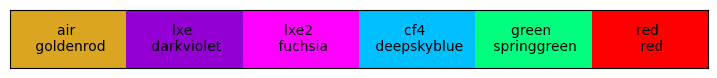

In [1]:
import matplotlib.pyplot as plt
import copy

from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PNJunction import * 


# rad2deg = 180/np.pi

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors() # turn off with "off" option

In [ ]:
fixedPars_Boring = {"quantum": False, "smoothSigma": 9/2.335, "dh":None, "window":True}

with open("input_systematics.json", 'r') as file:
    json_systematic = json.load(file)

FF1 = json_systematic["HPK_VUV4"]["input_systematics"]["FF"]
# FF1 = 0.55
tOxide_values = json_systematic["HPK_VUV4"]["input_systematics"]["tOxide"]
ttGood = tOxide_values[0] # good thickness in nm
# ttGood = 23
# ttGood = 19
# vOffset = json_systematic["HPK_VUV4"]["Voffset"][1]
vOffset = 0
peSat = 1.0

fixedPars_physics = {"FF": FF1, "Temperature": 160, "tOxide":ttGood}
fixedPars_parametrized = {"Ae":peSat, "Ah":1.0}

print(fixedPars_Boring)
print(fixedPars_physics)
print(fixedPars_parametrized)

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


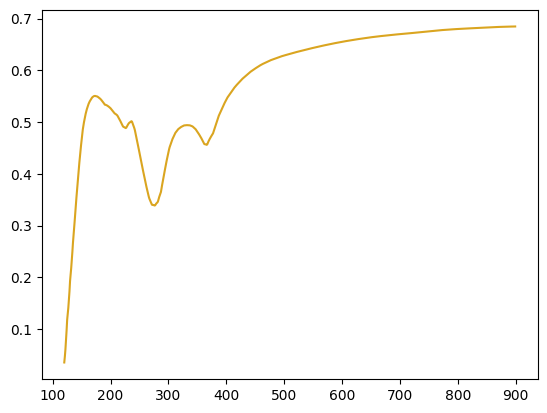

In [2]:
wlens = np.arange(120, 900, 1)

ph = PhotonInfo(wlens)

plt.plot(wlens, ph.Wave_TotalTransmission(16.8))